<a href="https://colab.research.google.com/github/Itodomanuel/colab-git-demo-EI/blob/main/Ai_Task_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import libraries for data handling
import pandas as pd
import numpy as np

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Import dataset
from sklearn.datasets import fetch_openml

# Import model selection tools
from sklearn.model_selection import train_test_split, GridSearchCV

# Import regression model
from sklearn.ensemble import RandomForestRegressor

# Import evaluation metrics
from sklearn.metrics import mean_squared_error, r2_score

# Set visualization style
sns.set_style("whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Load Boston Housing dataset
boston = fetch_openml(
    name="boston",
    version=1,
    as_frame=True
)

# Convert features into DataFrame
df = boston.data.copy()

# Add target variable
df["MEDV"] = pd.to_numeric(boston.target)

# Display dataset dimensions
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

# Display first five rows
df.head()

Dataset loaded successfully!
Dataset shape: (506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [3]:
# Show details
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


In [4]:
# Display dataset information
df.info()

# Display descriptive statistics
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   CRIM     506 non-null    float64 
 1   ZN       506 non-null    float64 
 2   INDUS    506 non-null    float64 
 3   CHAS     506 non-null    category
 4   NOX      506 non-null    float64 
 5   RM       506 non-null    float64 
 6   AGE      506 non-null    float64 
 7   DIS      506 non-null    float64 
 8   RAD      506 non-null    category
 9   TAX      506 non-null    float64 
 10  PTRATIO  506 non-null    float64 
 11  B        506 non-null    float64 
 12  LSTAT    506 non-null    float64 
 13  MEDV     506 non-null    float64 
dtypes: category(2), float64(12)
memory usage: 49.0 KB


,CRIM,ZN,INDUS,NOX,RM,AGE,DIS,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.554695,6.284634,68.574901,3.795043,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.115878,0.702617,28.148861,2.105710,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.385000,3.561000,2.900000,1.129600,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.449000,5.885500,45.025000,2.100175,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.538000,6.208500,77.500000,3.207450,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.624000,6.623500,94.075000,5.188425,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,0.871000,8.780000,100.000000,12.126500,711.000000,22.000000,396.900000,37.970000,50.000000


In [5]:
# Check missing values in each column
print(df.isnull().sum())

# Check total missing values
print("Total missing values:", df.isnull().sum().sum())


CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64
Total missing values: 0


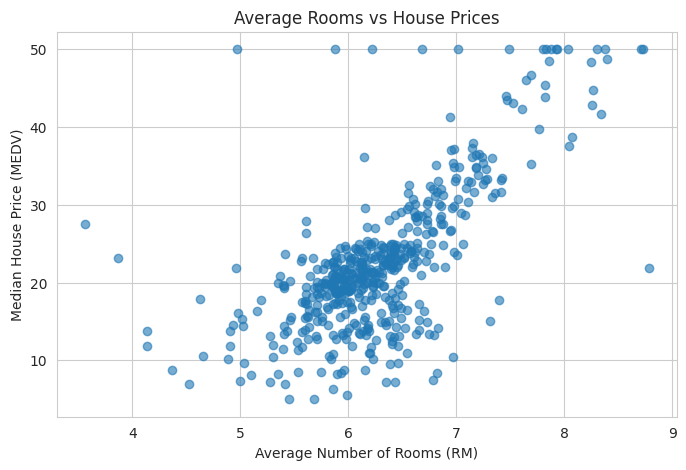

In [6]:
plt.figure(figsize=(8, 5))

plt.scatter(df["RM"], df["MEDV"], alpha=0.6)

plt.xlabel("Average Number of Rooms (RM)")
plt.ylabel("Median House Price (MEDV)")
plt.title("Average Rooms vs House Prices")

plt.show()

In [7]:
def plot_features(features, target, data):

    for feature in features:

        plt.figure(figsize=(7, 4))

        plt.scatter(
            data[feature],
            data[target],
            alpha=0.6
        )

        plt.xlabel(feature)
        plt.ylabel(target)
        plt.title(f"{feature} vs {target}")

        plt.tight_layout()
        plt.show()


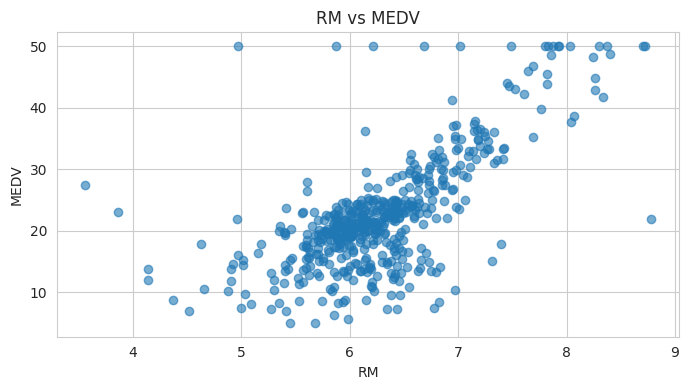

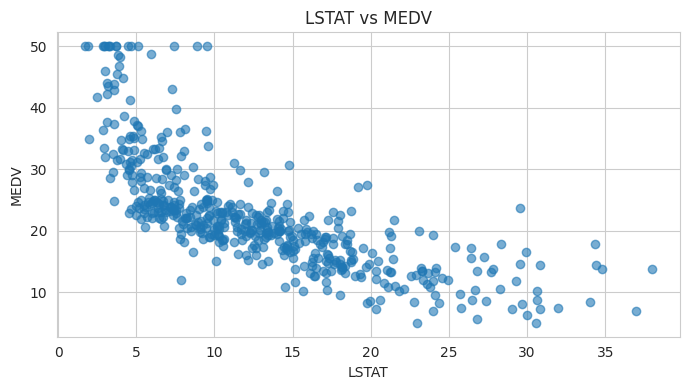

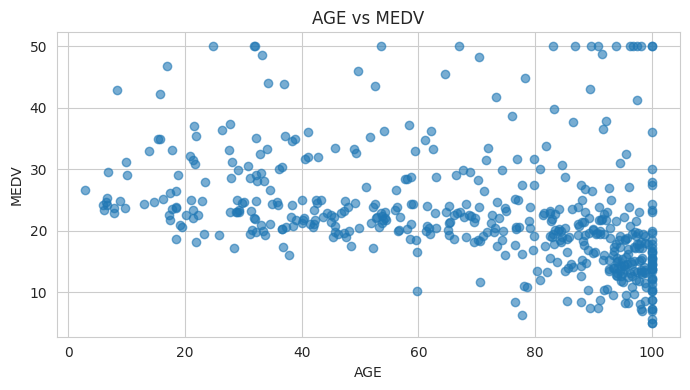

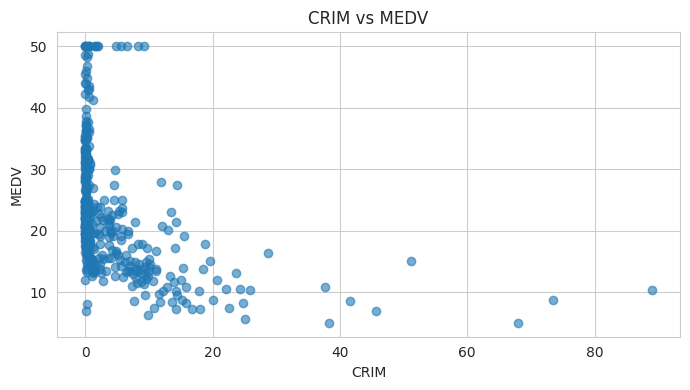

In [8]:
# Select features for visualization
selected_features = [
    "RM",
    "LSTAT",
    "AGE",
    "CRIM"
]

# Generate scatter plots
plot_features(
    selected_features,
    "MEDV",
    df
)

In [9]:
# Independent variables
X = df.drop("MEDV", axis=1)

# Dependent variable
y = df["MEDV"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (506, 13)
Target shape: (506,)


In [10]:
# Splitting test and train
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (404, 13)
Testing data: (102, 13)


In [11]:
# Initialize Random Forest Regressor
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

print("Random Forest model created successfully!")


Random Forest model created successfully!


In [12]:
# Train model
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [13]:
# Predict house prices using test data
y_pred = model.predict(X_test)


In [14]:
# Calculate RMSE
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# Calculate R-squared
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("RMSE:", round(rmse, 2))
print("R-squared:", round(r2, 4))


Model Evaluation Results
------------------------
RMSE: 2.81
R-squared: 0.8923


In [15]:
# Define hyperparameter combinations
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10, 15],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

# Initialize Grid Search
grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Perform hyperparameter tuning
grid_search.fit(X_train, y_train)

# Display best parameters
print("Best Parameters:", grid_search.best_params_)

Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}


In [16]:
# Select optimized model
best_model = grid_search.best_estimator_

# Make predictions
tuned_predictions = best_model.predict(X_test)

# Calculate optimized metrics
tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_predictions)
)

tuned_r2 = r2_score(y_test, tuned_predictions)

print("Optimized Model Results")
print("-----------------------")
print("RMSE:", round(tuned_rmse, 2))
print("R-squared:", round(tuned_r2, 4))

# Compare original and optimized models
print("\nModel Comparison")
print("Original RMSE:", round(rmse, 2))
print("Tuned RMSE:", round(tuned_rmse, 2))

print("Original R-squared:", round(r2, 4))
print("Tuned R-squared:", round(tuned_r2, 4))

Optimized Model Results
-----------------------
RMSE: 3.02
R-squared: 0.8758

Model Comparison
Original RMSE: 2.81
Tuned RMSE: 3.02
Original R-squared: 0.8923
Tuned R-squared: 0.8758


In [17]:
# Create new property data
new_house = pd.DataFrame([{
    "CRIM": 0.2,
    "ZN": 12.5,
    "INDUS": 7.07,
    "CHAS": 0,
    "NOX": 0.5,
    "RM": 6.5,
    "AGE": 68,
    "DIS": 4.0,
    "RAD": 2,
    "TAX": 250,
    "PTRATIO": 17,
    "B": 400,
    "LSTAT": 12
}])

# Predict house price
predicted_price = best_model.predict(new_house)

print(
    "Predicted House Price: $",
    round(predicted_price[0] * 1000, 2)
)

Predicted House Price: $ 22327.84


In [18]:
# Predict prices for test dataset
predictions = best_model.predict(X_test)

# Compare actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": predictions
})

print(comparison.head(10))

   Actual Price  Predicted Price
0          23.6        23.266129
1          32.4        30.797579
2          13.6        17.127080
3          22.8        23.321082
4          16.1        16.556372
5          20.0        21.416961
6          17.8        19.612176
7          14.0        15.977631
8          19.6        21.067978
9          16.8        21.311016


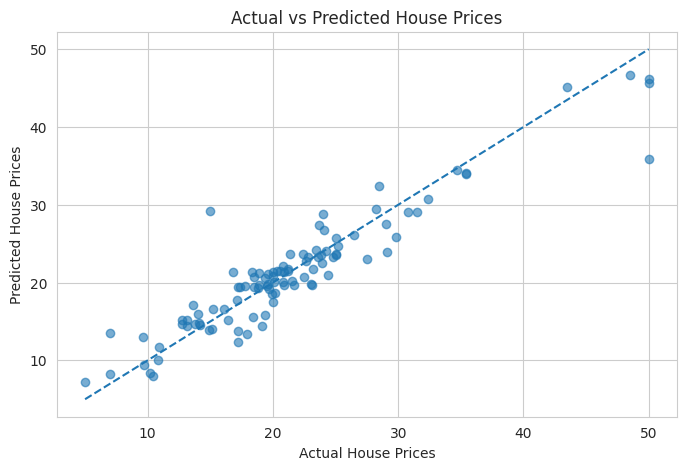

In [19]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, tuned_predictions, alpha=0.6)

# Reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")

plt.show()